Using cpu device
Epoch [1/5], Loss: 0.3432
Epoch [2/5], Loss: 0.1439
Epoch [3/5], Loss: 0.0999
Epoch [4/5], Loss: 0.0749
Epoch [5/5], Loss: 0.0584
Total Accuracy: 97.46%
Model saved to mnist_model.pth


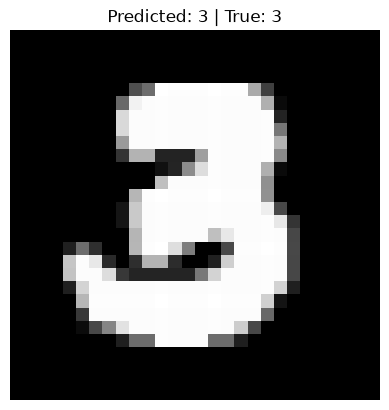

Predicted Label: 3
True Label: 3
User picked image index: 200


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision.datasets import MNIST
from torchvision import transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt


# 1. Device select karna
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")


# 2. MNIST dataset load karna
transform = transforms.ToTensor()

train_data = MNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

test_data = MNIST(
    root="data",
    train=False,
    download=True,
    transform=transform
)


# 3. DataLoaders banana
train_loader = DataLoader(
    train_data,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_data,
    batch_size=64,
    shuffle=False
)


# 4. Model banana
class DigitModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(28 * 28, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.net(x)


# 5. Model, loss function aur optimizer
model = DigitModel().to(device)

loss_fn = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)


# 6. Model train karna
epochs = 5

for epoch in range(epochs):

    model.train()
    total_loss = 0

    for images, labels in train_loader:

        # Images ko flatten karna
        images = images.view(images.size(0), -1).to(device)
        labels = labels.to(device)

        # Purane gradients zero karna
        optimizer.zero_grad()

        # Prediction
        outputs = model(images)

        # Loss calculate karna
        loss = loss_fn(outputs, labels)

        # Backpropagation
        loss.backward()

        # Model update karna
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    print(
        f"Epoch [{epoch + 1}/{epochs}], "
        f"Loss: {average_loss:.4f}"
    )


# 7. Model ki accuracy check karna
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.view(images.size(0), -1).to(device)
        labels = labels.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)


accuracy = 100 * correct / total

print(f"Total Accuracy: {accuracy:.2f}%")


# 8. Model save karna
torch.save(model.state_dict(), "mnist_model.pth")

print("Model saved to mnist_model.pth")


# 9. Test image select karna
index = 200

image, true_label = test_data[index]

# Image ko model ke liye prepare karna
image_flat = image.view(1, -1).to(device)


# 10. Prediction karna
model.eval()

with torch.no_grad():

    output = model(image_flat)

    predicted_label = output.argmax(dim=1).item()


# 11. Image display karna
plt.imshow(image.squeeze(), cmap="gray")

plt.title(
    f"Predicted: {predicted_label} | True: {true_label}"
)

plt.axis("off")
plt.show()


# 12. Result print karna
print(f"Predicted Label: {predicted_label}")
print(f"True Label: {true_label}")
print(f"User picked image index: {index}")